In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

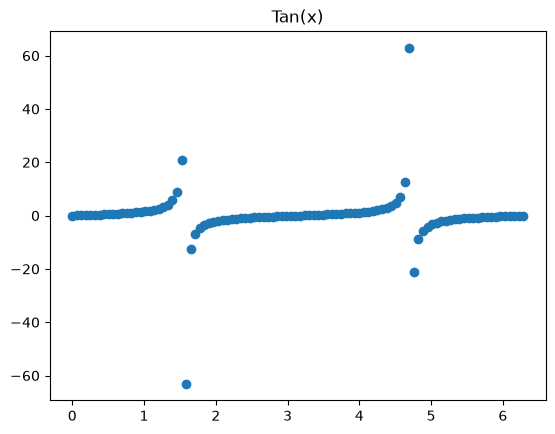

In [24]:
x = np.linspace(0, 2 * np.pi, 100)
y = np.tan(x)

plt.scatter(x, y)
plt.title("Tan(x)")
plt.show()

          x          y
0  0.000000   1.909918
1  0.204082   1.736152
2  0.408163   9.266035
3  0.612245   4.644937
4  0.816327  15.596592             x           y
45   9.183673  113.130937
46   9.387755  109.902028
47   9.591837  119.716504
48   9.795918  123.796965
49  10.000000  123.740302


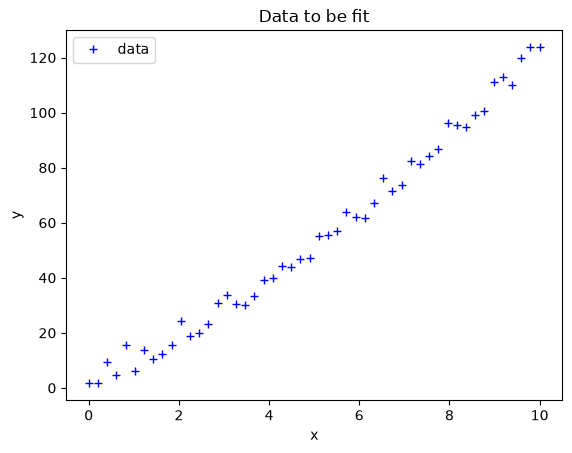

In [26]:
df = pd.read_csv("F26_cf_demo_data.csv")

print(df.head(), df.tail())

x = df["x"]
y = df["y"]

plt.plot(x, y, "b+", label = "data")
plt.title("Data to be fit")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

In [28]:
def linear(x, m, b):
    return m * x + b

In [29]:
popt, pcov = curve_fit(linear, x, y)

In [34]:
m_fit, b_fit = popt
print(f"line of best fit: {m_fit:.2f}x + {b_fit:.2f}")

line of best fit: 12.24x + -5.93


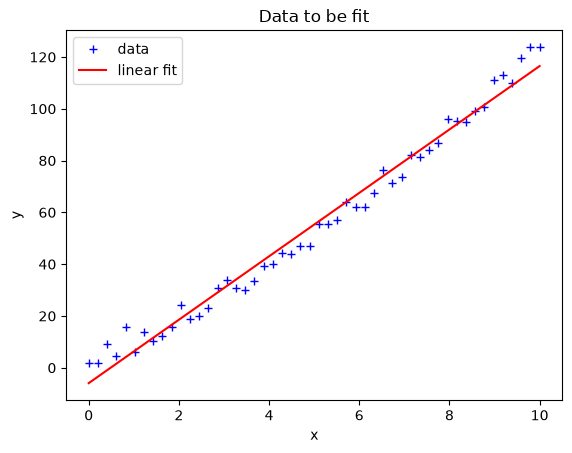

In [35]:
plt.plot(x, y, "b+", label = "data")
# y_fit = linear(x, m_fit, b_fit)
plt.plot(x, m_fit*x + b_fit, "r", label = "linear fit")
plt.title("Data to be fit")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

AttributeError: Line2D.set() got an unexpected keyword argument 'lavel'

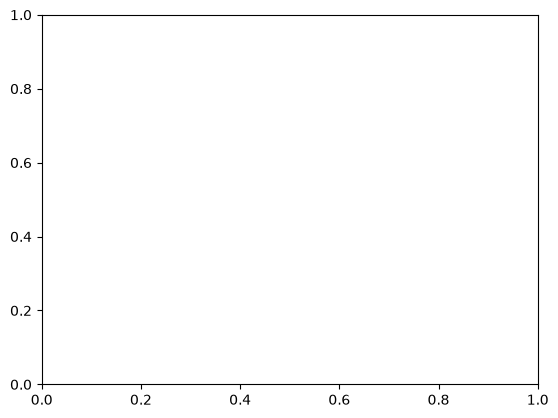

In [38]:
#line of best fit
plt.plot(x, linear(x, *popt), color = "red", lavel = "li fit")
plt.plot(x, y, "b+", label = "data")
plt.legend()
plt.show()

In [40]:
perr = np.sqrt(np.diag(pcov))
m_err, b_err = perr

print(f"Slope: m = {m_fit:.2f} +- {m_err:.2f}")

Slope: m = 12.24 +- 0.24


In [43]:
residuals = y - linear(x, *popt)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof\

print(f"reduced chi squared = {chi2_reduced:.3f}")

reduced chi squared = 24.665
